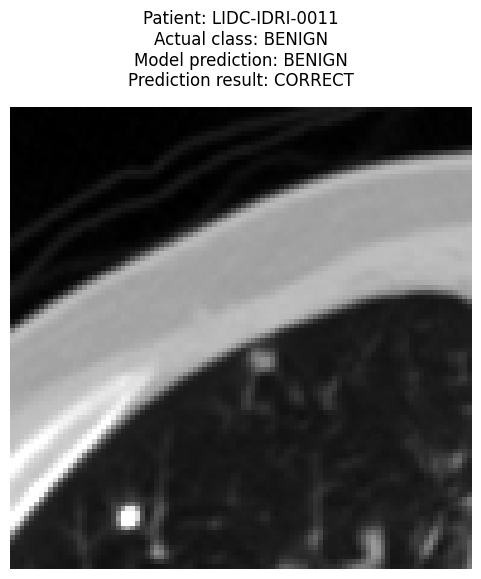

Patient ID       : LIDC-IDRI-0011
Image file       : nodule_1_-181.png
Ground truth     : BENIGN
Model prediction : BENIGN
Prediction       : CORRECT
Dataset role     : Held-out TEST sample


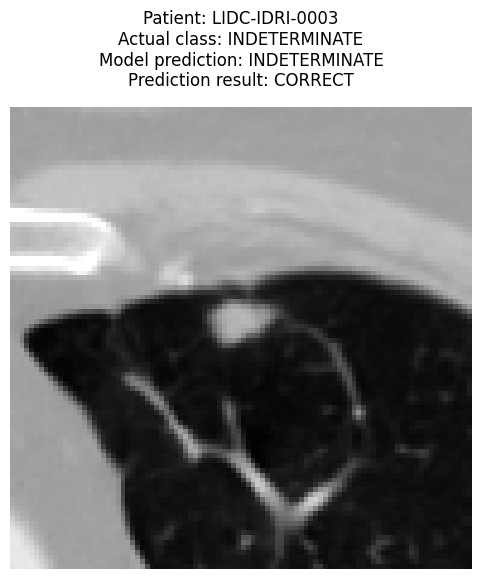

Patient ID       : LIDC-IDRI-0003
Image file       : nodule_21_-172.png
Ground truth     : INDETERMINATE
Model prediction : INDETERMINATE
Prediction       : CORRECT
Dataset role     : Held-out TEST sample


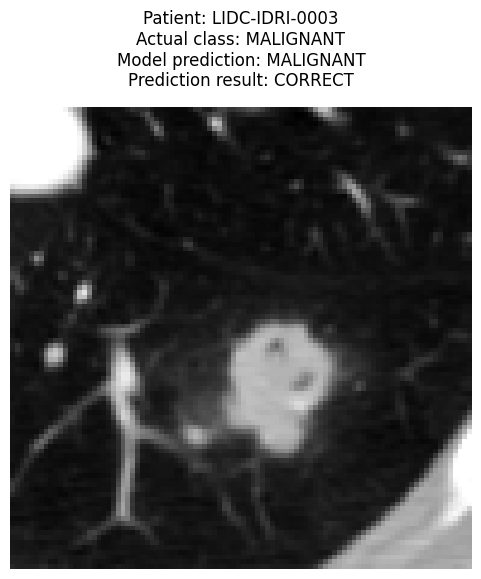

Patient ID       : LIDC-IDRI-0003
Image file       : nodule_0_-191.png
Ground truth     : MALIGNANT
Model prediction : MALIGNANT
Prediction       : CORRECT
Dataset role     : Held-out TEST sample


In [1]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

# Three real held-out test samples from your trained model
samples = [
    {
        "patient": "LIDC-IDRI-0011",
        "path": "/experiment-storage/chaidir/fawad-dsai/GLADS_CT Project/02_Matched_Benchmarks_and_LungDxFormer/LungDxFormer/data/processed/lidc_real/LIDC-IDRI-0011/nodule_1_-181.png",
        "actual": "BENIGN",
        "predicted": "BENIGN",
        "correct": True,
    },
    {
        "patient": "LIDC-IDRI-0003",
        "path": "/experiment-storage/chaidir/fawad-dsai/GLADS_CT Project/02_Matched_Benchmarks_and_LungDxFormer/LungDxFormer/data/processed/lidc_real/LIDC-IDRI-0003/nodule_21_-172.png",
        "actual": "INDETERMINATE",
        "predicted": "INDETERMINATE",
        "correct": True,
    },
    {
        "patient": "LIDC-IDRI-0003",
        "path": "/experiment-storage/chaidir/fawad-dsai/GLADS_CT Project/02_Matched_Benchmarks_and_LungDxFormer/LungDxFormer/data/processed/lidc_real/LIDC-IDRI-0003/nodule_0_-191.png",
        "actual": "MALIGNANT",
        "predicted": "MALIGNANT",
        "correct": True,
    },
]

for sample in samples:
    image_path = Path(sample["path"])
    
    img = Image.open(image_path).convert("L")

    plt.figure(figsize=(6, 6))
    plt.imshow(img, cmap="gray")
    plt.axis("off")

    result_text = (
        f"Patient: {sample['patient']}\n"
        f"Actual class: {sample['actual']}\n"
        f"Model prediction: {sample['predicted']}\n"
        f"Prediction result: {'CORRECT' if sample['correct'] else 'INCORRECT'}"
    )

    plt.title(result_text, fontsize=12, pad=15)
    plt.show()

    print("=" * 70)
    print(f"Patient ID       : {sample['patient']}")
    print(f"Image file       : {image_path.name}")
    print(f"Ground truth     : {sample['actual']}")
    print(f"Model prediction : {sample['predicted']}")
    print(f"Prediction       : {'CORRECT' if sample['correct'] else 'INCORRECT'}")
    print("Dataset role     : Held-out TEST sample")
    print("=" * 70)

Randomly selected HELD-OUT TEST samples


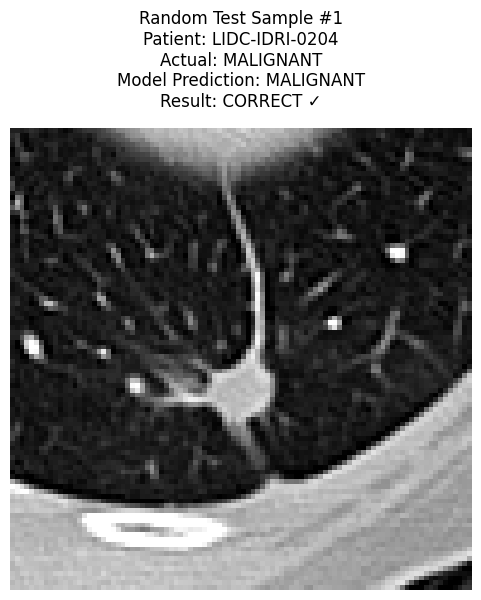


SAMPLE #1
----------------------------------------------------------------------
Patient ID       : LIDC-IDRI-0204
Image            : nodule_15_-284.png
Full path        : /experiment-storage/chaidir/fawad-dsai/GLADS_CT Project/02_Matched_Benchmarks_and_LungDxFormer/LungDxFormer/data/processed/lidc_real/LIDC-IDRI-0204/nodule_15_-284.png
Ground truth     : MALIGNANT
Model prediction : MALIGNANT
Prediction result: CORRECT
Dataset role     : HELD-OUT TEST SET
----------------------------------------------------------------------


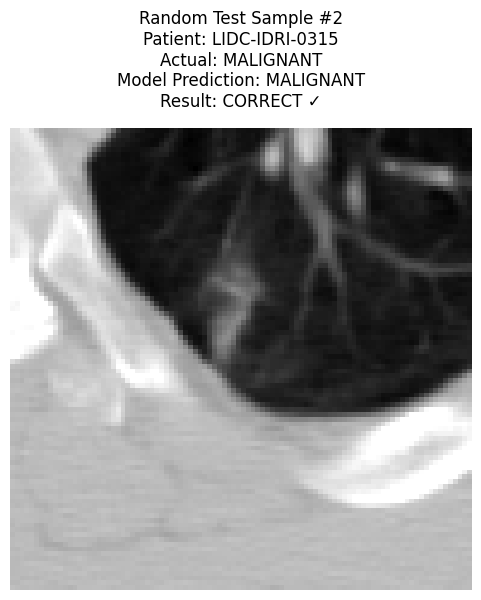


SAMPLE #2
----------------------------------------------------------------------
Patient ID       : LIDC-IDRI-0315
Image            : nodule_2_1569.png
Full path        : /experiment-storage/chaidir/fawad-dsai/GLADS_CT Project/02_Matched_Benchmarks_and_LungDxFormer/LungDxFormer/data/processed/lidc_real/LIDC-IDRI-0315/nodule_2_1569.png
Ground truth     : MALIGNANT
Model prediction : MALIGNANT
Prediction result: CORRECT
Dataset role     : HELD-OUT TEST SET
----------------------------------------------------------------------


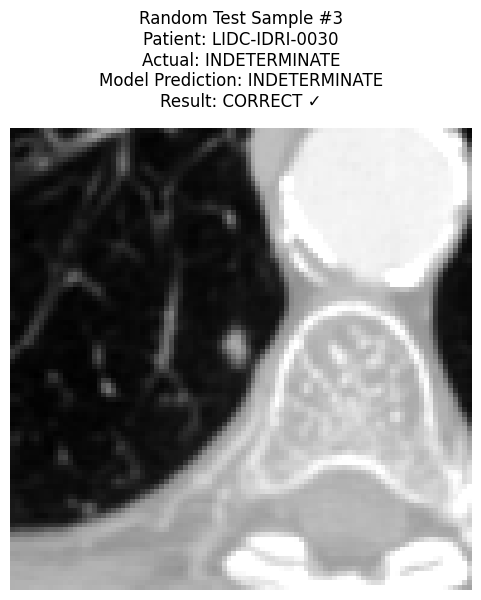


SAMPLE #3
----------------------------------------------------------------------
Patient ID       : LIDC-IDRI-0030
Image            : nodule_23_-89.png
Full path        : /experiment-storage/chaidir/fawad-dsai/GLADS_CT Project/02_Matched_Benchmarks_and_LungDxFormer/LungDxFormer/data/processed/lidc_real/LIDC-IDRI-0030/nodule_23_-89.png
Ground truth     : INDETERMINATE
Model prediction : INDETERMINATE
Prediction result: CORRECT
Dataset role     : HELD-OUT TEST SET
----------------------------------------------------------------------


In [3]:
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------------------------
# Load predictions from the held-out TEST set
# ---------------------------------------------------------
predictions_file = (
    "/experiment-storage/chaidir/fawad-dsai/GLADS_CT Project/02_Matched_Benchmarks_and_LungDxFormer/LungDxFormer/"
    "outputs/lidc_real/predictions/test_predictions.csv"
)

df = pd.read_csv(predictions_file)

# Class mapping used by the model
class_names = {
    0: "BENIGN",
    1: "INDETERMINATE",
    2: "MALIGNANT"
}

# ---------------------------------------------------------
# RANDOMLY select 3 test samples
# random_state=None means different samples each time
# ---------------------------------------------------------
samples = df.sample(n=3, random_state=None)

print("Randomly selected HELD-OUT TEST samples")
print("=" * 70)

# ---------------------------------------------------------
# Display each real CT/nodule image
# ---------------------------------------------------------
for i, (_, row) in enumerate(samples.iterrows(), start=1):

    image_path = Path(row["path"])

    actual_class = class_names[int(row["y_true"])]
    predicted_class = class_names[int(row["y_pred"])]

    correct = int(row["y_true"]) == int(row["y_pred"])

    # Extract patient ID from path
    patient_id = image_path.parent.name

    # Load image
    img = Image.open(image_path).convert("L")

    # Display image
    plt.figure(figsize=(6, 6))
    plt.imshow(img, cmap="gray")
    plt.axis("off")

    plt.title(
        f"Random Test Sample #{i}\n"
        f"Patient: {patient_id}\n"
        f"Actual: {actual_class}\n"
        f"Model Prediction: {predicted_class}\n"
        f"Result: {'CORRECT ✓' if correct else 'INCORRECT ✗'}",
        fontsize=12,
        pad=15
    )

    plt.show()

    # Detailed textual information
    print(f"\nSAMPLE #{i}")
    print("-" * 70)
    print(f"Patient ID       : {patient_id}")
    print(f"Image            : {image_path.name}")
    print(f"Full path        : {image_path}")
    print(f"Ground truth     : {actual_class}")
    print(f"Model prediction : {predicted_class}")
    print(f"Prediction result: {'CORRECT' if correct else 'INCORRECT'}")
    print(f"Dataset role     : HELD-OUT TEST SET")
    print("-" * 70)

Random held-out example from each diagnostic class


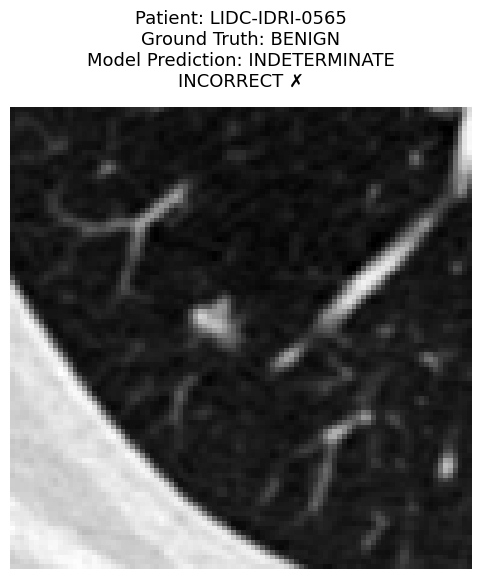

Patient          : LIDC-IDRI-0565
CT/Nodule image  : nodule_12_-222.png
Actual diagnosis : BENIGN
Model prediction : INDETERMINATE
Correct?         : NO
Source           : Held-out test set


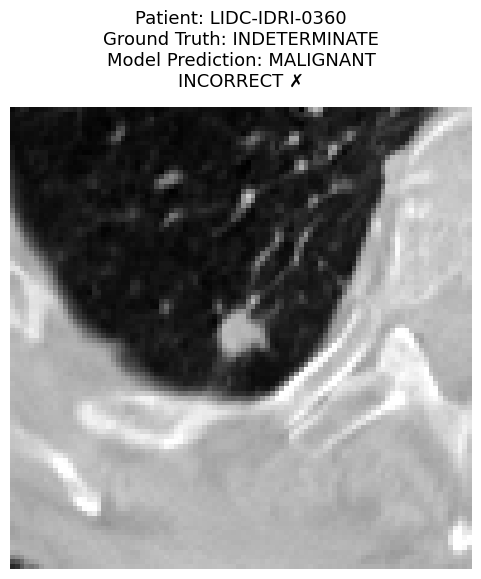

Patient          : LIDC-IDRI-0360
CT/Nodule image  : nodule_13_-711.png
Actual diagnosis : INDETERMINATE
Model prediction : MALIGNANT
Correct?         : NO
Source           : Held-out test set


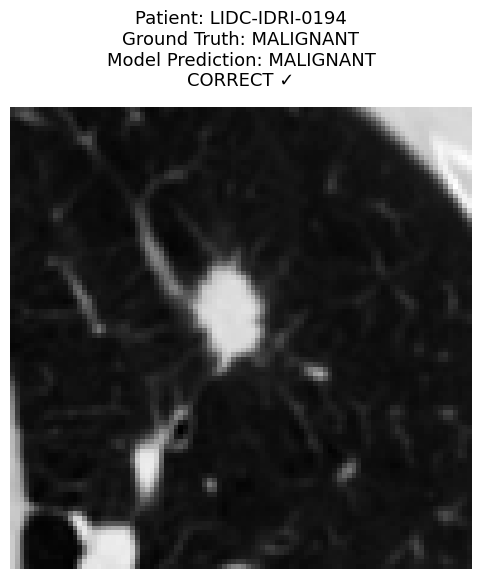

Patient          : LIDC-IDRI-0194
CT/Nodule image  : nodule_9_-134.png
Actual diagnosis : MALIGNANT
Model prediction : MALIGNANT
Correct?         : YES
Source           : Held-out test set


In [4]:
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

predictions_file = (
    "/experiment-storage/chaidir/fawad-dsai/GLADS_CT Project/02_Matched_Benchmarks_and_LungDxFormer/LungDxFormer/"
    "outputs/lidc_real/predictions/test_predictions.csv"
)

df = pd.read_csv(predictions_file)

class_names = {
    0: "BENIGN",
    1: "INDETERMINATE",
    2: "MALIGNANT"
}

# Select ONE RANDOM test example from each class
samples = []

for class_id in [0, 1, 2]:
    random_sample = df[df["y_true"] == class_id].sample(n=1)
    samples.append(random_sample.iloc[0])

print("Random held-out example from each diagnostic class")
print("=" * 70)

for i, row in enumerate(samples, start=1):

    image_path = Path(row["path"])

    actual = class_names[int(row["y_true"])]
    predicted = class_names[int(row["y_pred"])]

    correct = int(row["y_true"]) == int(row["y_pred"])

    patient_id = image_path.parent.name

    img = Image.open(image_path).convert("L")

    plt.figure(figsize=(6, 6))
    plt.imshow(img, cmap="gray")
    plt.axis("off")

    plt.title(
        f"Patient: {patient_id}\n"
        f"Ground Truth: {actual}\n"
        f"Model Prediction: {predicted}\n"
        f"{'CORRECT ✓' if correct else 'INCORRECT ✗'}",
        fontsize=13,
        pad=15
    )

    plt.show()

    print("=" * 70)
    print(f"Patient          : {patient_id}")
    print(f"CT/Nodule image  : {image_path.name}")
    print(f"Actual diagnosis : {actual}")
    print(f"Model prediction : {predicted}")
    print(f"Correct?         : {'YES' if correct else 'NO'}")
    print("Source           : Held-out test set")
    print("=" * 70)